# 02 - Confronto sistematico sui carichi prandiali (paziente fisso: adult#001)

**Obiettivo.** Confrontare il PID standard e il controllore IOB-constrained su pasti non annunciati da 30, 60 e 90 g di carboidrati, mantenendo fisso il paziente.

**Condizioni identiche per i due controllori.** Stesso paziente, stesso sensore e stesso seme del rumore, stesse condizioni iniziali, stessa durata e passo, stesso pasto, stessi guadagni, stesso target e stessi limiti dell'attuatore. L'unica differenza è l'attivazione del tetto IOB e della sospensione predittiva (verificato nella tabella 1.2).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import aid_sim as A, notebook_utils as U
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 110)
SEED = 1                      # seme del rumore del sensore (uguale per tutti i controllori)
PID  = {}                     # PID di riferimento: parametri di default di AIDController
PROP = dict(use_iob=True, use_plgs=True)   # controllore proposto: stesso PID + tetto IOB + PLGS
print("Versioni delle librerie usate:"); display(U.library_versions())

Versioni delle librerie usate:


,Pacchetto,Versione
0,Python,3.12.3
1,simglucose,0.2.11
2,numpy,2.4.4
3,scipy,1.17.1
4,pandas,3.0.2
5,matplotlib,3.10.8


## 1. Configurazione
### 1.1 Scenario

In [2]:
PAZIENTE = 'adult#001'
ub = U.initial_conditions(PAZIENTE, SEED)['ub']
display(U.scenario_table(PAZIENTE, '30, 60 o 90', SEED))

,Voce,Valore,Unita'
0,Paziente virtuale,adult#001,-
1,Peso corporeo BW,102.3,kg
2,Glicemia basale di equilibrio Gb,138.6,mg/dL
3,Fabbisogno basale nominale u_b,1.267,U/h
4,Sensore CGM,Dexcom (rumore autoregressivo UVA/Padova),-
5,Pompa di infusione,Insulet,-
6,Seme casuale sensore (seed),1,-
7,Inizio simulazione,08:00,ora solare
8,Durata simulazione,16.0,h
9,Passo di campionamento dt,3.0,min


### 1.2 Parametri dei due controllori affiancati (differenze evidenziate)

In [3]:
a = U.controller_table(PID, ub).set_index('Parametro'); b = U.controller_table(PROP, ub).set_index('Parametro')
cmp_ = pd.DataFrame({"PID": a['Valore'], "PID + IOB + PLGS": b['Valore'], "Unita'": a["Unita'"]})
cmp_['Diverso?'] = np.where(cmp_['PID'].astype(str) != cmp_['PID + IOB + PLGS'].astype(str), 'SI', '')
display(cmp_)
print("Parametri che differiscono:", list(cmp_.index[cmp_['Diverso?'] == 'SI']))

,PID,PID + IOB + PLGS,Unita',Diverso?
Parametro,,,,
target,120.0,120.0,mg/dL,
kp,0.0001,0.0001,U/min per mg/dL,
ki,0.000005,0.000005,U/min per (mg/dL*min),
kd,0.002,0.002,U/min per (mg/dL/min),
i_min,-2000.0,-2000.0,mg*min/dL,
i_max,10000.0,10000.0,mg*min/dL,
use_iob,False,True,-,SI
iob_alpha,1.5,1.5,adimensionale,
tau_s,50.0,50.0,min,


Parametri che differiscono: ['use_iob', 'use_plgs']


### 1.3 Unità di misura
`t_h` [h dall'inizio], `BG`/`CGM` [mg/dL], `Insulin_Uh` [U/h], `IOB` [U]. Metriche in percentuale del tempo (TIR, TAR, TBR) o in mg/dL (picco, nadir).

## 2. Simulazioni

In [4]:
CARICHI = [30.0, 60.0, 90.0]
R = {(c, n): A.simulate(PAZIENTE, c, kw, seed=SEED)[0] for c in CARICHI for n, kw in [('PID', PID), ('PID+IOB+PLGS', PROP)]}
print(len(R), 'simulazioni completate')

6 simulazioni completate


## 3. Grafici: glicemia, infusione e IOB per ciascun carico

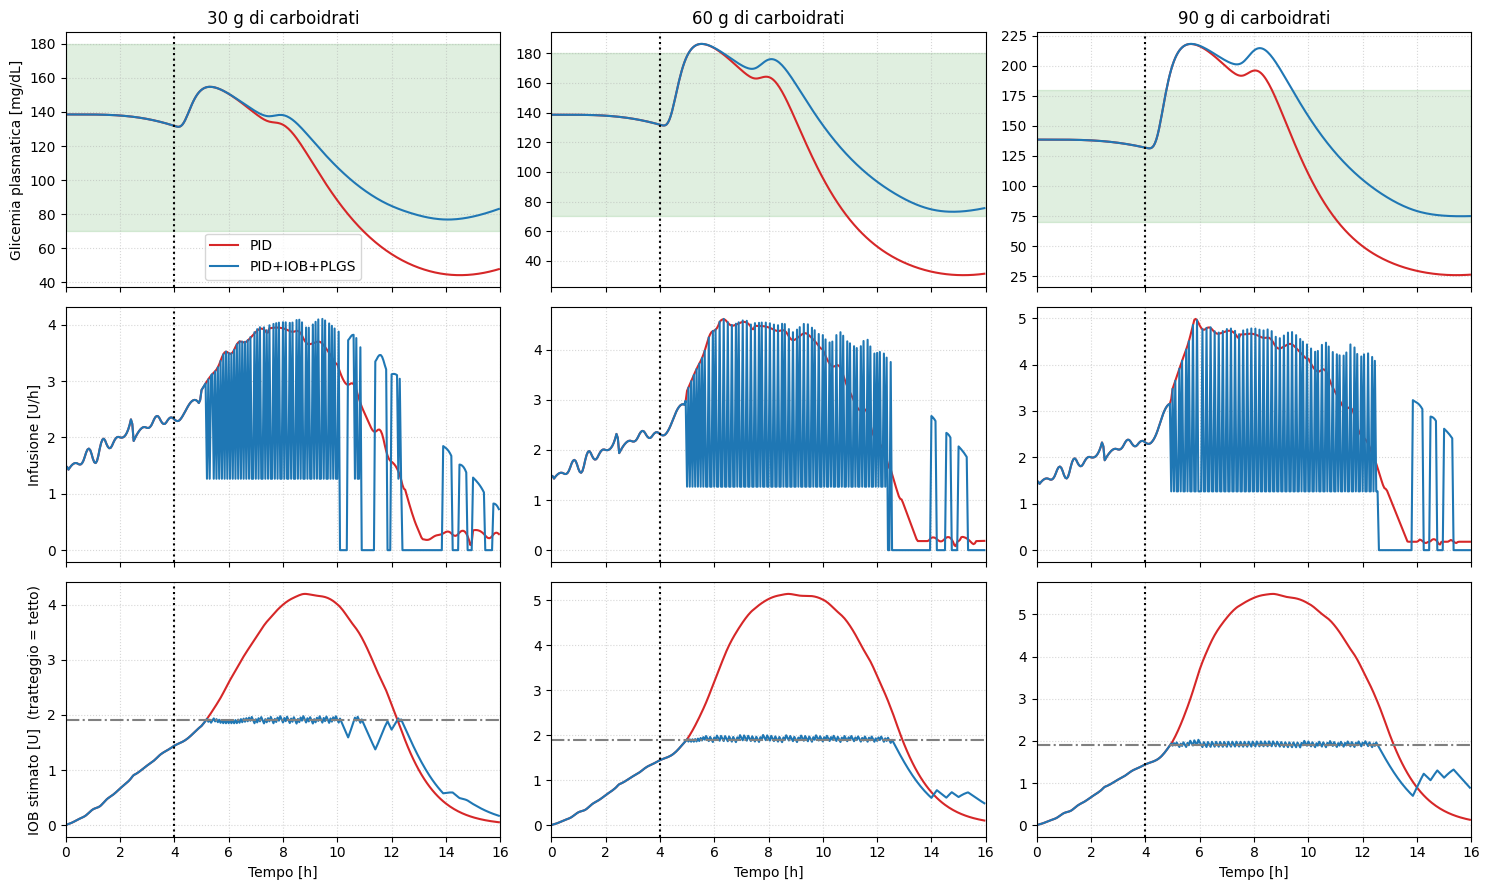

In [5]:
fig, ax = plt.subplots(3, 3, figsize=(15, 9), sharex=True)
for j, c in enumerate(CARICHI):
    for n, col in [('PID', 'tab:red'), ('PID+IOB+PLGS', 'tab:blue')]:
        d = R[(c, n)]; ax[0, j].plot(d.t_h, d.BG, color=col, label=n); ax[1, j].plot(d.t_h, d.Insulin_Uh, color=col); ax[2, j].plot(d.t_h, d.IOB, color=col)
    ax[2, j].axhline(1.5*ub*60, color='gray', ls='-.')
    ax[0, j].axhspan(70, 180, color='green', alpha=.12); ax[0, j].set_title(f'{int(c)} g di carboidrati')
    for i in range(3): ax[i, j].axvline(A.MEAL_OFFSET_H, color='k', ls=':'); ax[i, j].grid(ls=':', alpha=.5)
    ax[2, j].set_xlabel('Tempo [h]'); ax[2, j].set_xlim(0, 16)
ax[0, 0].set_ylabel('Glicemia plasmatica [mg/dL]'); ax[1, 0].set_ylabel('Infusione [U/h]'); ax[2, 0].set_ylabel('IOB stimato [U]  (tratteggio = tetto)')
ax[0, 0].legend(); plt.tight_layout(); plt.show()

## 4. Indicatori clinici

In [6]:
rows = []
for (c, n), d in R.items():
    m = A.metrics(d); rows.append({'CHO [g]': int(c), 'Controllore': n, **{k: round(float(v), 1) for k, v in m.items()}})
T = pd.DataFrame(rows).sort_values(['CHO [g]', 'Controllore'], ascending=[True, False]).reset_index(drop=True)
display(T)
D = T[T.Controllore == 'PID+IOB+PLGS'].set_index('CHO [g]').drop(columns='Controllore') - T[T.Controllore == 'PID'].set_index('CHO [g]').drop(columns='Controllore')
print("Differenza (proposto - PID):"); display(D.round(1))

,CHO [g],Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,picco,nadir
0,30,PID+IOB+PLGS,100.0,0.0,0.0,0.0,0.0,0.0,154.8,76.8
1,30,PID,68.8,0.0,0.0,31.2,23.1,55.6,154.8,44.1
2,60,PID+IOB+PLGS,92.2,7.8,0.0,0.0,0.0,0.0,186.3,73.1
3,60,PID,60.6,7.5,0.0,31.9,26.6,56.7,186.3,30.4
4,90,PID+IOB+PLGS,70.9,29.1,0.0,0.0,0.0,0.0,218.2,74.8
5,90,PID,45.0,24.4,0.0,30.6,26.2,54.4,218.1,25.8


Differenza (proposto - PID):


,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,picco,nadir
CHO [g],,,,,,,,
30,31.2,0.0,0.0,-31.2,-23.1,-55.6,0.0,32.7
60,31.6,0.3,0.0,-31.9,-26.6,-56.7,0.0,42.7
90,25.9,4.7,0.0,-30.6,-26.2,-54.4,0.1,49.0


## 5. Lettura dei risultati (calcolata dalla tabella)

In [7]:
for c in [30, 60, 90]:
    p = T[(T['CHO [g]'] == c) & (T.Controllore == 'PID')].iloc[0]; q = T[(T['CHO [g]'] == c) & (T.Controllore == 'PID+IOB+PLGS')].iloc[0]
    print(f"{c:2d} g: picco {p['picco']:.0f} -> {q['picco']:.0f} mg/dL | TIR {p['TIR']:.1f} -> {q['TIR']:.1f} % | "
          f"TBR {p['TBR']:.1f} -> {q['TBR']:.1f} % | TBR tardivo {p['TBR_tardivo']:.1f} -> {q['TBR_tardivo']:.1f} % | nadir {p['nadir']:.0f} -> {q['nadir']:.0f} mg/dL")

30 g: picco 155 -> 155 mg/dL | TIR 68.8 -> 100.0 % | TBR 31.2 -> 0.0 % | TBR tardivo 55.6 -> 0.0 % | nadir 44 -> 77 mg/dL
60 g: picco 186 -> 186 mg/dL | TIR 60.6 -> 92.2 % | TBR 31.9 -> 0.0 % | TBR tardivo 56.7 -> 0.0 % | nadir 30 -> 73 mg/dL
90 g: picco 218 -> 218 mg/dL | TIR 45.0 -> 70.9 % | TBR 30.6 -> 0.0 % | TBR tardivo 54.4 -> 0.0 % | nadir 26 -> 75 mg/dL


**Nota sul seme.** Questo notebook usa un solo seme del rumore. La robustezza rispetto al rumore del sensore (5 semi, 60 g) è in `results/robustezza_semi.csv`, generato da `run_campaign.py`.